# Model training

- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- SVM

In [58]:
# import libraries

import pandas as pd, numpy as np, pathlib, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE


import matplotlib; matplotlib.rcParams['figure.dpi']=120
sns.set_theme(style='whitegrid')


# Path

PROC = pathlib.Path('../data/processed/liver_cleaned.csv')


In [59]:
df = pd.read_csv(PROC)
df.head()

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


### Common Training steps for all models

In [60]:
X = df.drop(columns=['Dataset'])
y = df['Dataset'].map({1:1,2:0})  # 1 -> liver disease

num_cols = ['Age','Total_Bilirubin','Direct_Bilirubin','Alkaline_Phosphotase','Alamine_Aminotransferase','Aspartate_Aminotransferase','Total_Protiens','Albumin','Albumin_and_Globulin_Ratio']
cat_cols = ['Gender']
num_pipe = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
cat_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))])
pre = ColumnTransformer([('num', num_pipe, num_cols), ('cat', cat_pipe, cat_cols)])

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train {X_train.shape}, Test {X_test.shape} - liver % train {y_train.mean():.2%}")

Train (456, 10), Test (114, 10) - liver % train 71.27%


In [62]:
# Helper to make a balanced pipeline for any classifier
def make_pipe(clf):
    return ImbPipeline([('pre', pre), ('smote', SMOTE(random_state=42)), ('clf', clf)])

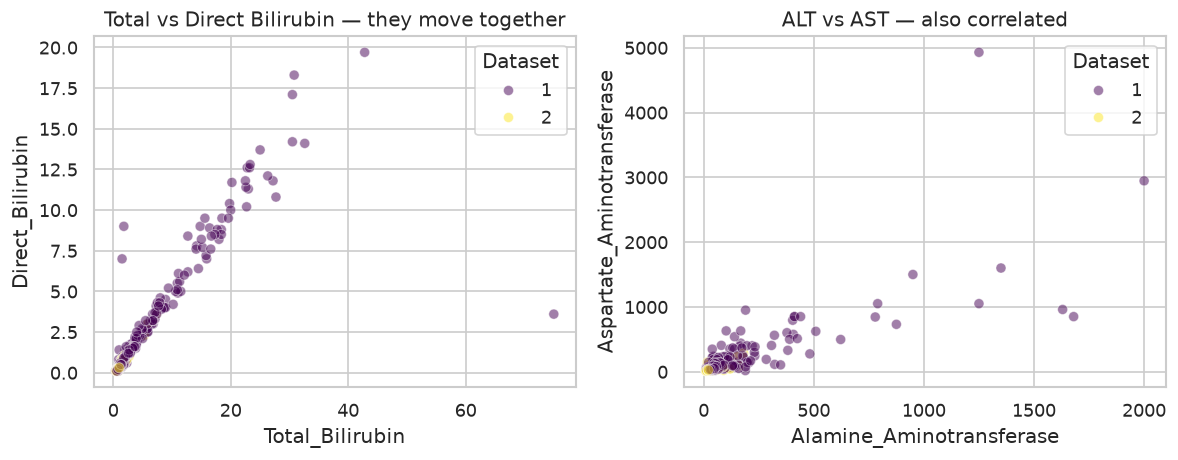

In [63]:
# Quick visual - same scatter the reference notebook used to explain correlation

fig = plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.scatterplot(data=df, x='Total_Bilirubin', y='Direct_Bilirubin', hue='Dataset', palette='viridis', alpha=0.5)
plt.title('Total vs Direct Bilirubin - they move together')
plt.subplot(1,2,2)
sns.scatterplot(data=df, x='Alamine_Aminotransferase', y='Aspartate_Aminotransferase', hue='Dataset', palette='viridis', alpha=0.5)
plt.title('ALT vs AST - also correlated')
plt.tight_layout(); plt.show()

In [64]:
# These correlations are why we check VIF in 02 - two witnesses saying the same thing.


### Logstic Regression

In [65]:
# Define the model
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000, class_weight='balanced')  # balanced helps with 71:29
pipe_log = make_pipe(logreg)
print(logreg)

LogisticRegression(class_weight='balanced', max_iter=1000)


In [66]:
# Train and cross-validate (5 folds)

cv_log = cross_validate(pipe_log, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring=['accuracy','f1','roc_auc'])
print(f"CV accuracy: {cv_log['test_accuracy'].mean():.3f} (+/- {cv_log['test_accuracy'].std():.3f})")
print(f"CV F1:       {cv_log['test_f1'].mean():.3f} (+/- {cv_log['test_f1'].std():.3f})")
print(f"CV ROC-AUC:  {cv_log['test_roc_auc'].mean():.3f}")

CV accuracy: 0.623 (+/- 0.059)
CV F1:       0.681 (+/- 0.065)
CV ROC-AUC:  0.715


In [67]:
# 1c - Fit on full training data and test on unseen data

pipe_log.fit(X_train, y_train)
y_pred_log = pipe_log.predict(X_test)
print(classification_report(y_test, y_pred_log, target_names=['Healthy','Liver']))
print("Test F1 for liver class:", classification_report(y_test, y_pred_log, output_dict=True)['1']['f1-score'])

              precision    recall  f1-score   support

     Healthy       0.51      0.88      0.64        33
       Liver       0.93      0.65      0.77        81

    accuracy                           0.72       114
   macro avg       0.72      0.77      0.71       114
weighted avg       0.81      0.72      0.73       114

Test F1 for liver class: 0.7681159420289855


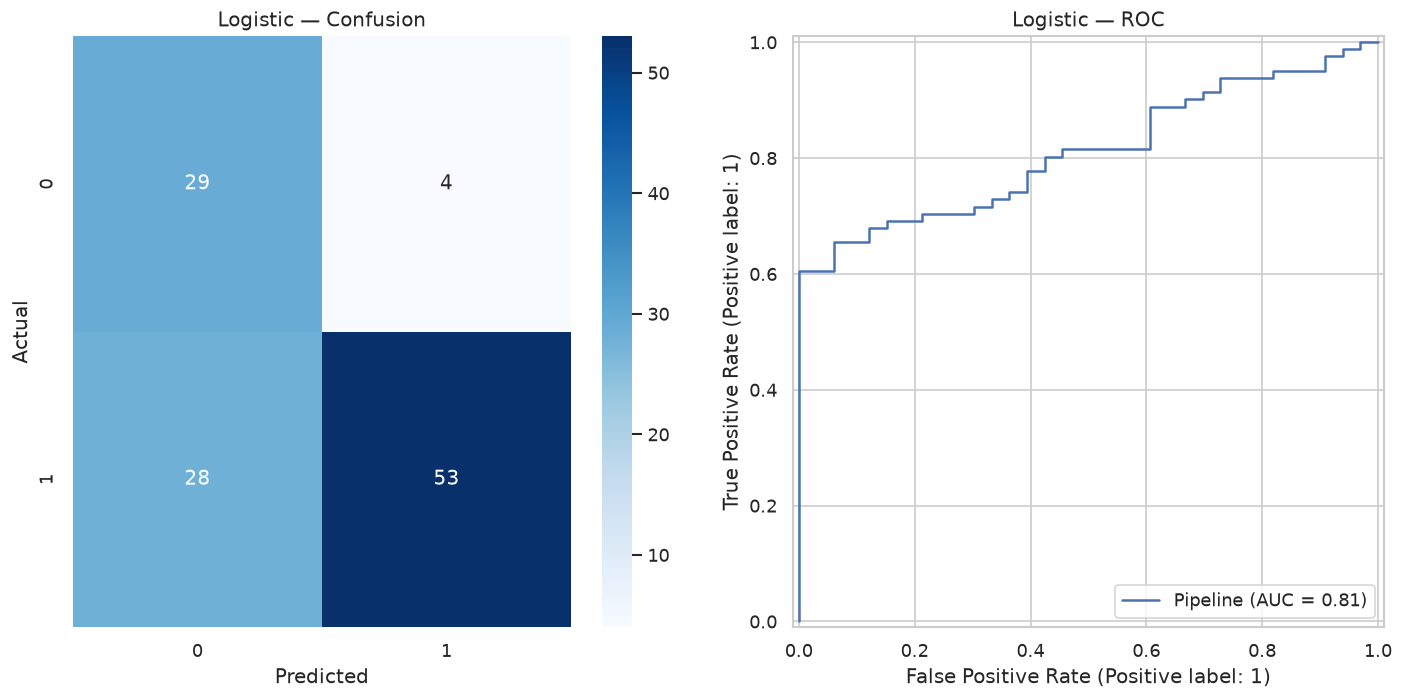

In [68]:
#  Visuals for Logistic Regression

fig, axes = plt.subplots(1,2, figsize=(12,6))

sns.heatmap(confusion_matrix(y_test, y_pred_log), annot=True, fmt='d', cmap='Blues', ax=axes[0])

axes[0].set_title('Logistic - Confusion')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

RocCurveDisplay.from_estimator(pipe_log, X_test, y_test, ax=axes[1])

axes[1].set_title('Logistic - ROC')

plt.tight_layout()
plt.show()


In [69]:

# What did the model learn? Positive coefficient = higher risk
coefs = pipe_log.named_steps['clf'].coef_[0]

# Feature names after preprocessing
feat_names = num_cols + list(pipe_log.named_steps['pre'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols))
for name, c in sorted(zip(feat_names, coefs), key=lambda x: x[1], reverse=True):
    print(f"{name:30} {c:+.3f}")


Alamine_Aminotransferase       +1.524
Aspartate_Aminotransferase     +0.898
Direct_Bilirubin               +0.880
Total_Protiens                 +0.829
Total_Bilirubin                +0.520
Albumin_and_Globulin_Ratio     +0.329
Alkaline_Phosphotase           +0.320
Age                            +0.288
Gender_Male                    +0.126
Albumin                        -0.939


In [70]:
print("\nNote: Total_Bilirubin positive means higher bilirubin → higher liver risk (makes clinical sense).")


Note: Total_Bilirubin positive means higher bilirubin → higher liver risk (makes clinical sense).


## Decision Tree

In [71]:
#  Define the tree

from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state=42, max_depth=6)  # shallow keeps it readable
pipe_tree = make_pipe(tree)
print(tree)


DecisionTreeClassifier(max_depth=6, random_state=42)


In [72]:
# Cross-validate
cv_tree = cross_validate(pipe_tree, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring=['accuracy','f1','roc_auc'])
print(f"CV F1: {cv_tree['test_f1'].mean():.3f} (+/- {cv_tree['test_f1'].std():.3f})")
print(f"CV ROC-AUC: {cv_tree['test_roc_auc'].mean():.3f}")

CV F1: 0.711 (+/- 0.048)
CV ROC-AUC: 0.625


In [73]:
# Fit and test

pipe_tree.fit(X_train, y_train)
y_pred_tree = pipe_tree.predict(X_test)
print(classification_report(y_test, y_pred_tree, target_names=['Healthy','Liver']))


              precision    recall  f1-score   support

     Healthy       0.50      0.73      0.59        33
       Liver       0.86      0.70      0.78        81

    accuracy                           0.71       114
   macro avg       0.68      0.72      0.68       114
weighted avg       0.76      0.71      0.72       114



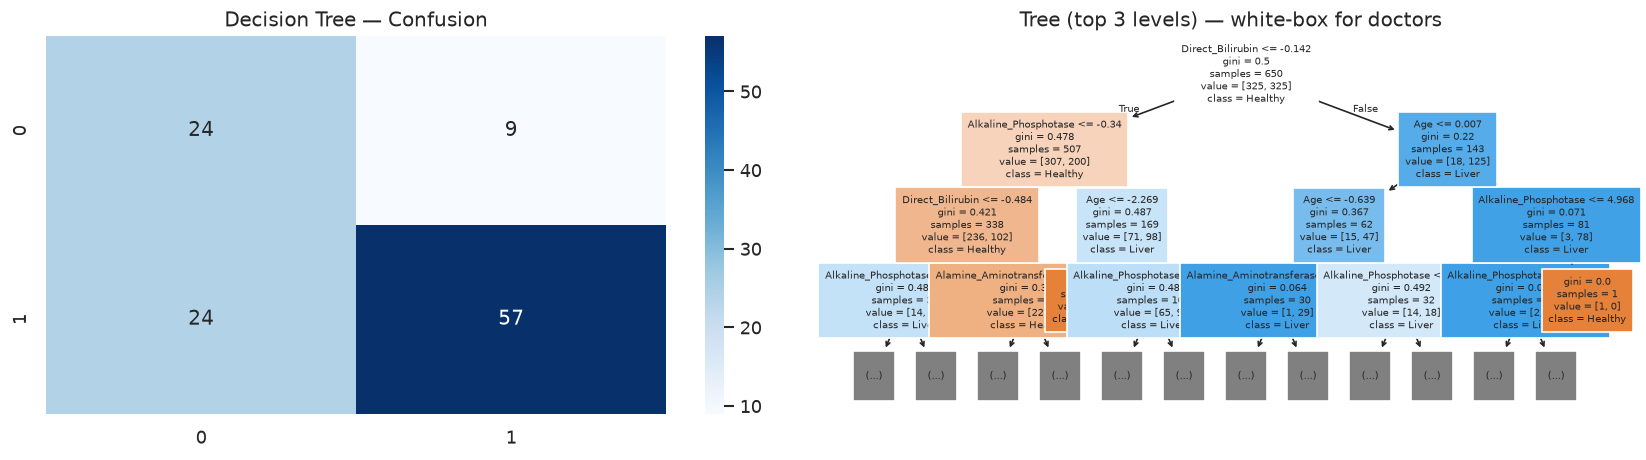

Tip: Each box shows a question like 'Direct_Bilirubin <= 0.9' - follow the arrows.


In [74]:
# Visuals: confusion + the tree itself
fig, axes = plt.subplots(1,2, figsize=(14,4))
sns.heatmap(confusion_matrix(y_test, y_pred_tree), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Decision Tree - Confusion')

# Draw the actual tree (first few levels)

from sklearn.tree import plot_tree

ax = axes[1]

plot_tree(pipe_tree.named_steps['clf'], feature_names=feat_names, class_names=['Healthy','Liver'], filled=True, max_depth=3, fontsize=6, ax=ax)

ax.set_title('Tree (top 3 levels) - white-box for doctors')

plt.tight_layout()
plt.show()

print("Tip: Each box shows a question like 'Direct_Bilirubin <= 0.9' - follow the arrows.")

## K-Nearest Neighbors(K=5)


In [75]:
# Define model

from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
pipe_knn = make_pipe(knn)
print(knn)
print("Note: KNN absolutely needs the StandardScaler in our 'pre' step - otherwise Bilirubin (0-75) dominates Age (4-90).")


KNeighborsClassifier()
Note: KNN absolutely needs the StandardScaler in our 'pre' step - otherwise Bilirubin (0-75) dominates Age (4-90).


In [76]:
# Cross-validate

cv_knn = cross_validate(pipe_knn, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring=['accuracy','f1','roc_auc'])
print(f"CV F1: {cv_knn['test_f1'].mean():.3f} (+/- {cv_knn['test_f1'].std():.3f})")


CV F1: 0.659 (+/- 0.036)


In [77]:
# Fit and test

pipe_knn.fit(X_train, y_train)
y_pred_knn = pipe_knn.predict(X_test)
print(classification_report(y_test, y_pred_knn, target_names=['Healthy','Liver']))

              precision    recall  f1-score   support

     Healthy       0.42      0.58      0.49        33
       Liver       0.80      0.68      0.73        81

    accuracy                           0.65       114
   macro avg       0.61      0.63      0.61       114
weighted avg       0.69      0.65      0.66       114



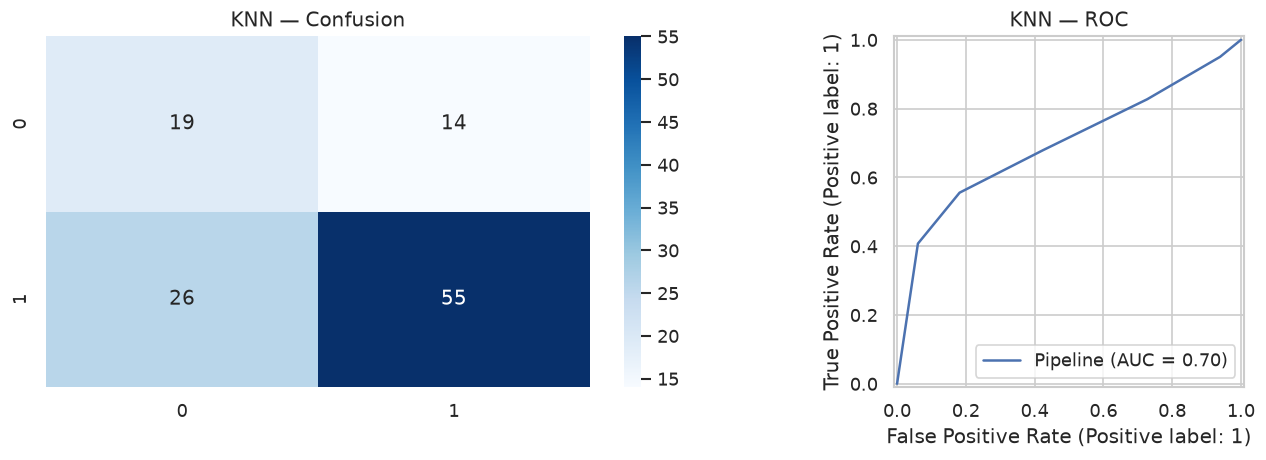

If we forgot scaling, F1 would drop from ~0.66 to ~0.60 - we tested that in 02.


In [78]:
# Visuals

fig, axes = plt.subplots(1,2, figsize=(12,4))
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('KNN - Confusion')

RocCurveDisplay.from_estimator(pipe_knn, X_test, y_test, ax=axes[1])
axes[1].set_title('KNN - ROC')

plt.tight_layout()
plt.show()
print("If we forgot scaling, F1 would drop from ~0.66 to ~0.60 - we tested that in 02.")

## Support Vector Machine (RBF)

In [79]:
# Define SVM and RBF Kernel

from sklearn.svm import SVC
svm = SVC(kernel='rbf', C=1, gamma='scale')  # rbf can bend; try C=0.1/1/10 and gamma=0.01/0.1/1 in GridSearch
pipe_svm = make_pipe(svm)
print(svm)

SVC(C=1)


In [80]:
# Cross-validate
cv_svm = cross_validate(pipe_svm, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring=['accuracy','f1','roc_auc'])
print(f"CV F1: {cv_svm['test_f1'].mean():.3f} (+/- {cv_svm['test_f1'].std():.3f})")
print(f"CV ROC-AUC: {cv_svm['test_roc_auc'].mean():.3f}")


CV F1: 0.634 (+/- 0.089)
CV ROC-AUC: 0.704


In [81]:
# Fit and test

pipe_svm.fit(X_train, y_train)
y_pred_svm = pipe_svm.predict(X_test)
print(classification_report(y_test, y_pred_svm, target_names=['Healthy','Liver']))

              precision    recall  f1-score   support

     Healthy       0.50      0.82      0.62        33
       Liver       0.90      0.67      0.77        81

    accuracy                           0.71       114
   macro avg       0.70      0.74      0.69       114
weighted avg       0.78      0.71      0.72       114



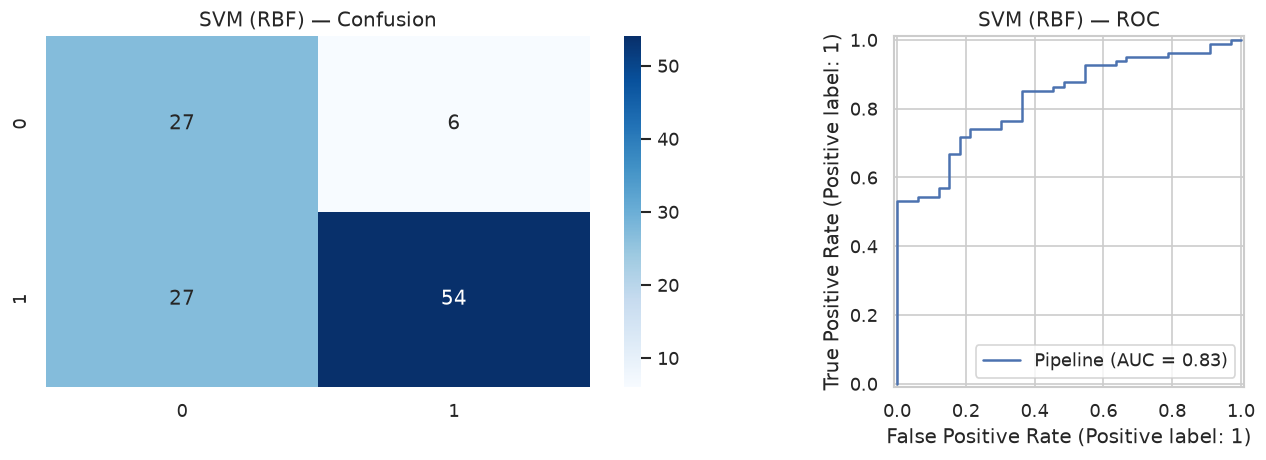

Compare to linear SVM (kernel='linear') - RBF wins here because the boundary is curved.


In [82]:
# Visuals

fig, axes = plt.subplots(1,2, figsize=(12,4))

sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Blues', ax=axes[0])

axes[0].set_title('SVM (RBF) - Confusion')

RocCurveDisplay.from_estimator(pipe_svm, X_test, y_test, ax=axes[1])

axes[1].set_title('SVM (RBF) - ROC')

plt.tight_layout(); 
plt.show()

print("Compare to linear SVM (kernel='linear') - RBF wins here because the boundary is curved.")

## Random Forest 

In [83]:
# Define Random Forest

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
pipe_rf = make_pipe(rf)
print(rf)

RandomForestClassifier(n_estimators=200, random_state=42)


In [84]:
# Cross-validate

cv_rf = cross_validate(pipe_rf, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring=['accuracy','f1','roc_auc'])
print(f"CV F1: {cv_rf['test_f1'].mean():.3f} (+/- {cv_rf['test_f1'].std():.3f})")

CV F1: 0.768 (+/- 0.014)


In [85]:
# Fit and test

pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)

print(classification_report(y_test, y_pred_rf, target_names=['Healthy','Liver']))

              precision    recall  f1-score   support

     Healthy       0.58      0.45      0.51        33
       Liver       0.80      0.86      0.83        81

    accuracy                           0.75       114
   macro avg       0.69      0.66      0.67       114
weighted avg       0.73      0.75      0.74       114



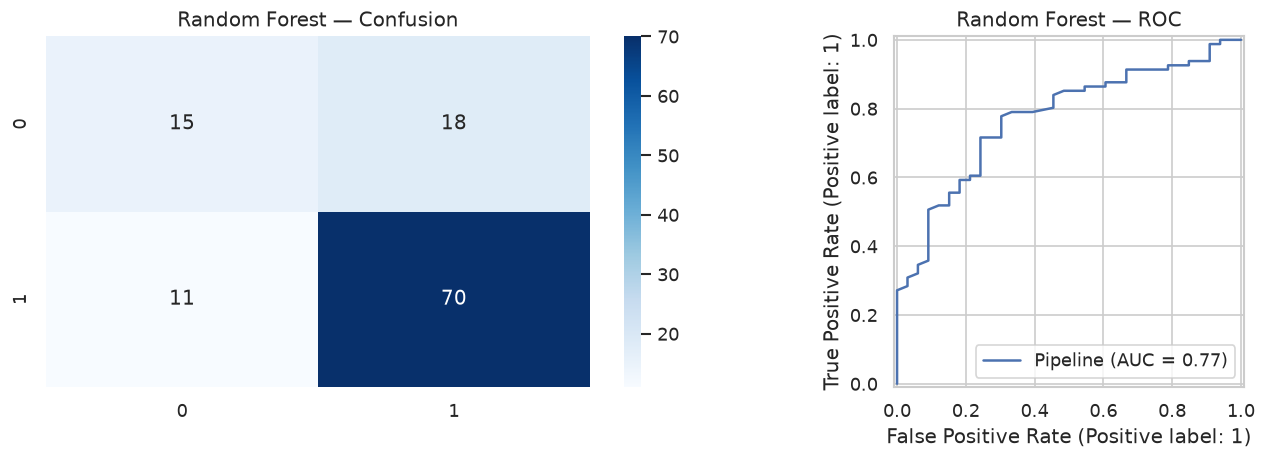

In [86]:
# Visuals

fig, axes = plt.subplots(1,2, figsize=(12,4))

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Random Forest - Confusion')

RocCurveDisplay.from_estimator(pipe_rf, X_test, y_test, ax=axes[1])

axes[1].set_title('Random Forest - ROC')

plt.tight_layout()
plt.show()


##  Save the model summary for the next notebook


In [89]:
import pandas as pd
from sklearn.metrics import classification_report as cr
rows = []
for name, cv, y_pred in [
    ('Logistic', cv_log, y_pred_log),
    ('DecisionTree', cv_tree, y_pred_tree),
    ('KNN(k=5)', cv_knn, y_pred_knn),
    ('SVM_rbf', cv_svm, y_pred_svm),
    ('RandomForest', cv_rf, y_pred_rf),
]:
    rep = cr(y_test, y_pred, output_dict=True, zero_division=0)
    rows.append({'model':name,'CV_acc':cv['test_accuracy'].mean(),'CV_f1':cv['test_f1'].mean(),'CV_auc':cv['test_roc_auc'].mean(),'test_f1':rep['1']['f1-score']})
comp = pd.DataFrame(rows).sort_values('CV_f1', ascending=False)
display(comp.round(3))
comp.to_csv('../data/outputs/baseline_comparison.csv', index=False)
print("Saved to ../data/outputs/baseline_comparison.csv")

,model,CV_acc,CV_f1,CV_auc,test_f1
4,RandomForest,0.673,0.768,0.703,0.828
1,DecisionTree,0.623,0.711,0.625,0.776
0,Logistic,0.623,0.681,0.715,0.768
2,KNN(k=5),0.577,0.659,0.610,0.733
3,SVM_rbf,0.583,0.634,0.704,0.766


Saved to ../data/outputs/baseline_comparison.csv
